# Class Activation Maps (CAMs) with the Best Model: DenseNet121

We do not train a new model here. We load the trained DenseNet121 weights and use **Grad-CAM** to visualize which regions of each ultrasound image contribute most to the model's prediction.

**Why DenseNet121?** It has the best Accuracy (0.9154), macro Precision, Recall and F1 among the three models, the fewest misclassified test images (11 of 130), and the highest recall on the malignant class (0.87). ResNet50 has a slightly higher AUC (0.9355 vs 0.9274), but the difference is small.

**Background**: Grad-CAM takes the gradients of the predicted class score with respect to the feature maps of the last convolutional stage, averages them into channel weights, and computes a weighted sum of the feature maps. The result is a heatmap (red = high contribution) that is overlaid on the input image.

## 1. Imports and settings

This cell imports the libraries and defines the paths. The CAM images will be saved to a separate folder, `cams_densenet121`.

In [1]:
import os, numpy as np, pandas as pd, torch, torch.nn as nn
from PIL import Image
from torchvision import models, transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = os.path.expanduser("~/Instruction1/outputs")
IMG_DIR = os.path.expanduser("~/datasets/Dataset_BUSI_with_GT_Clean/images")
CAM_DIR = os.path.expanduser("~/Instruction1/cams_densenet121")
os.makedirs(CAM_DIR, exist_ok=True)
class_names = {0: "malignant", 1: "benign"}
print("device:", device)


device: cpu


## 2. Load the trained DenseNet121

We rebuild the architecture with a 2-class output layer and load the saved weights (`densenet121_busi.pth`). The model is set to evaluation mode. No training is performed.

In [2]:
model = models.densenet121(weights=None)
model.classifier = nn.Linear(model.classifier.in_features, 2)
model.load_state_dict(torch.load(os.path.join(OUT_DIR, "densenet121_busi.pth"), map_location="cpu"))
model = model.to(device).eval()

## 3. Load the test images

The image list, true labels and saved predictions come from `test_predictions_densenet121.csv` (130 test images). Each image is preprocessed exactly as in training (224×224, ImageNet normalization). We also keep the un-normalized 224×224 RGB image in [0, 1], which is the background for the heatmap overlay.

In [3]:
pred_df = pd.read_csv(os.path.join(OUT_DIR, "test_predictions_densenet121.csv"))

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

pil_imgs = [Image.open(os.path.join(IMG_DIR, f)).convert("RGB").resize((224, 224)) for f in pred_df["Image"]]
rgb_imgs = [np.asarray(im, dtype=np.float32) / 255.0 for im in pil_imgs]   # for overlay
input_tensor = torch.stack([preprocess(Image.open(os.path.join(IMG_DIR, f)).convert("RGB")) for f in pred_df["Image"]])
print(input_tensor.shape)   # expected: [130, 3, 224, 224]

torch.Size([130, 3, 224, 224])


## 4. Generate Grad-CAM heatmaps and save them

The target layer is `model.features[-1]`, the last layer of the DenseNet feature extractor. By default Grad-CAM explains the class with the highest score, i.e. the model's **predicted class**. Gradients are required, so we do not use `torch.no_grad()`.

Each overlay is saved as `<index>_<image name>_true-<label>_pred-<label>_<OK/WRONG>.png`, so misclassified images can be found easily in the folder. We also check that the class predicted here matches the saved prediction file.

In [5]:
target_layers = [model.features[-1]]
n_saved, n_mismatch = 0, 0

with GradCAM(model=model, target_layers=target_layers) as cam:
    for start in range(0, len(input_tensor), 16):
        batch = input_tensor[start:start+16].to(device)
        heatmaps = cam(input_tensor=batch, targets=None)                      # [B, 224, 224], values in [0, 1]
        with torch.no_grad():
            preds = model(batch).argmax(1).cpu().numpy()
        for j in range(len(batch)):
            i = start + j
            overlay = show_cam_on_image(rgb_imgs[i], heatmaps[j], use_rgb=True)
            t, p = int(pred_df["True"][i]), int(preds[j])
            n_mismatch += int(p != int(pred_df["Pred"][i]))
            status = "OK" if t == p else "WRONG"
            stem = os.path.splitext(os.path.basename(pred_df["Image"][i]))[0]
            fname = f"{i:03d}_{stem}_true-{class_names[t]}_pred-{class_names[p]}_{status}.png"
            Image.fromarray(overlay).save(os.path.join(CAM_DIR, fname))
            n_saved += 1

print("saved:", n_saved, "| predictions differing from csv:", n_mismatch)

saved: 130 | predictions differing from csv: 0


## 5. Visual inspection

This cell shows the original image next to its CAM overlay for several correctly classified and several misclassified test images (green title = correct, red = wrong).

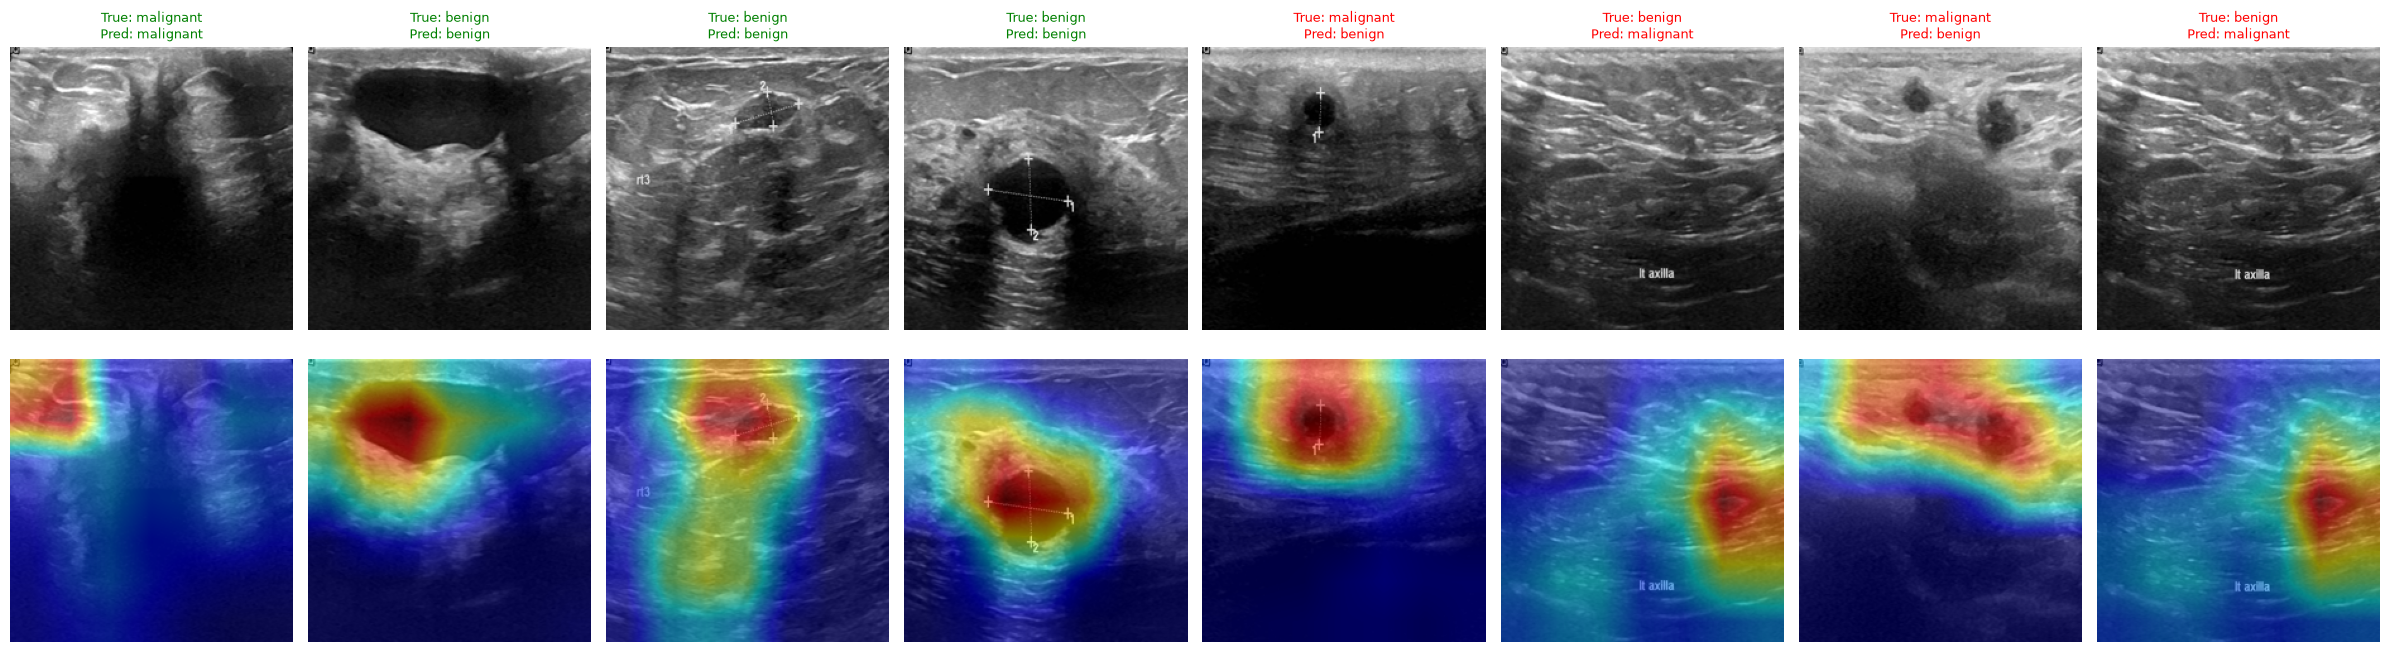

In [6]:
ok_idx = [i for i in range(len(pred_df)) if pred_df["True"][i] == pred_df["Pred"][i]][:4]
wrong_idx = [i for i in range(len(pred_df)) if pred_df["True"][i] != pred_df["Pred"][i]][:4]

fig, axes = plt.subplots(2, 8, figsize=(24, 7))
for k, i in enumerate(ok_idx + wrong_idx):
    stem = os.path.splitext(os.path.basename(pred_df["Image"][i]))[0]
    t, p = int(pred_df["True"][i]), int(pred_df["Pred"][i])
    status = "OK" if t == p else "WRONG"
    cam_file = [f for f in os.listdir(CAM_DIR) if f.startswith(f"{i:03d}_")][0]
    row, col = (0, k) if k < 4 else (1, k - 4)
    axes[row, col*2 if False else col].axis("off")
    ax_img = axes[0, k] ; ax_cam = axes[1, k]
    ax_img.imshow(rgb_imgs[i]); ax_img.axis("off")
    ax_cam.imshow(Image.open(os.path.join(CAM_DIR, cam_file))); ax_cam.axis("off")
    ax_img.set_title(f"True: {class_names[t]}\nPred: {class_names[p]}", fontsize=9,
                     color="green" if t == p else "red")
plt.tight_layout(); plt.show()

## 6. Observations

- For correctly classified images, the high-activation (red) region is **often on the lesion** (e.g., the benign cases in columns 2-4, where the heatmap follows the dark lesion), but not always: in the first malignant example the activation is concentrated in the top-left corner rather than on the central dark region.
- For misclassified images, the heatmap **sometimes still covers the lesion** (a malignant image predicted as benign has its peak on the dark region), and sometimes **focuses on a different area** (two benign images predicted as malignant have their peak in the lower-right, close to a text annotation).
- Malignant vs. benign: [fill in after reviewing all images].
- Possible shortcuts: in at least two misclassified images, the strongest activation lies near the text label at the bottom of the ultrasound image. This suggests the model may partly use non-tissue cues, but this needs to be confirmed on all images.
- Limitation: Grad-CAM is a coarse (7×7 resolution upsampled) explanation of the model's evidence, not proof that the model reasons like a clinician. These observations are based on a small number of examples and are qualitative.